# 09 — Task A vs Task B: does leakage matter, and where? (issue #17)

Notebooks 07 and 10 ran the *same* analysis code (`ehrgraph.netstats.task_analysis`) on the two locked tasks. This notebook puts them side by side:

| | Task A: Long Length of Stay | Task B: Hypertension |
|---|---|---|
| Predicts | Will this stay be long? | First hypertension diagnosis within a year? |
| Predicted at | End of the admission day | End of the discharge day |
| Is the outcome itself a diagnosis code? | **No** | **Yes** |

The last row is why the comparison matters. Our leaky graph lets each node see diagnoses from its whole record, including the future. For Task B, the future record can contain the answer itself.

**This notebook reads only `results/aggregate/*.csv`.** It needs no patient data, so anyone can run it, and so could CI.

In [1]:
import sys
from pathlib import Path

_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists() and _repo_root != _repo_root.parent:
    _repo_root = _repo_root.parent
sys.path.insert(0, str(_repo_root))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from ehrgraph.viz import network_figures as nf  # noqa: E402

results_dir = _repo_root / "results" / "aggregate"
figures_dir = results_dir / "figures"
TASKS = {"guo_los": "Task A: Long Length of Stay", "new_hypertension": "Task B: Hypertension"}
df = pd.concat(
    [pd.read_csv(results_dir / f) for f in ("network_stats_task_a.csv", "network_stats_task_b.csv")]
)
df = df[df["seed"].isna()]  # ensemble summaries and real graphs; per-seed null rows excluded
nf.apply_style()


def value(task, condition, metric, col="value"):
    hit = df[(df["task"] == task) & (df["condition"] == condition) & (df["metric"] == metric)]
    return float(hit[col].iloc[0]) if len(hit) else np.nan


print(df.groupby("task")["metric"].count())

task
guo_los             169
new_hypertension    169
Name: metric, dtype: int64


## The comparison in one table

Every row is one number per task and graph. Null values are the mean of 10 rewired graphs.

In [2]:
METRICS = {
    "prevalence": "Outcome base rate",
    "class_insensitive_homophily": "Homophily (0 = random)",
    "class_insensitive_homophily_excl_same_patient": "Homophily, without same-patient links",
    "dirichlet_energy_clmbr": "Dirichlet energy (lower = neighbors alike)",
    "leiden_outcome_eta_squared": "Outcome variance explained by community (η²)",
    "leiden_modularity": "Modularity",
    "transitivity": "Transitivity (closed triangles)",
    "largest_cc_fraction": "Share in largest piece",
    "same_patient_edge_fraction": "Share of links that are same-patient",
    "max_single_code_outcome_gap": "Largest single-code positive-negative gap",
}
rows = []
for metric, label in METRICS.items():
    for task, task_label in TASKS.items():
        conds = ("reference",) if metric == "prevalence" else ("safe", "leaky", "null_model")
        rows.append(
            {"metric": label, "task": task_label}
            | {c if c != "reference" else "safe": value(task, c, metric) for c in conds}
        )
table = pd.DataFrame(rows).set_index(["metric", "task"])
table["leaky − safe"] = table["leaky"] - table["safe"]
table.round(3)

safe  \
metric                                       task                                 
Outcome base rate                            Task A: Long Length of Stay  0.254   
                                             Task B: Hypertension         0.128   
Homophily (0 = random)                       Task A: Long Length of Stay  0.211   
                                             Task B: Hypertension         0.226   
Homophily, without same-patient links        Task A: Long Length of Stay  0.239   
                                             Task B: Hypertension         0.115   
Dirichlet energy (lower = neighbors alike)   Task A: Long Length of Stay  0.688   
                                             Task B: Hypertension         0.653   
Outcome variance explained by community (η²) Task A: Long Length of Stay  0.109   
                                             Task B: Hypertension         0.074   
Modularity                                   Task A: Long Length of Stay  0.938   
                                             Task B: Hypertension         0.922   
Transitivity (closed triangles)              Task A: Long Length of Stay  0.494   
                                             Task B: Hypertension         0.479   
Share in largest piece                       Task A: Long Length of Stay  0.882   
                                             Task B: Hypertension         0.880   
Share of links that are same-patient         Task A: Long Length of Stay  0.378   
                                             Task B: Hypertension         0.294   
Largest single-code positive-negative gap    Task A: Long Length of Stay  0.185   
                                             Task B: Hypertension         0.108   

                                                                          leaky  \
metric                                       task                                 
Outcome base rate                            Task A: Long Length of Stay    NaN   
                                             Task B: Hypertension           NaN   
Homophily (0 = random)                       Task A: Long Length of Stay  0.201   
                                             Task B: Hypertension         0.263   
Homophily, without same-patient links        Task A: Long Length of Stay  0.228   
                                             Task B: Hypertension         0.154   
Dirichlet energy (lower = neighbors alike)   Task A: Long Length of Stay  0.688   
                                             Task B: Hypertension         0.657   
Outcome variance explained by community (η²) Task A: Long Length of Stay  0.130   
                                             Task B: Hypertension         0.136   
Modularity                                   Task A: Long Length of Stay  0.977   
                                             Task B: Hypertension         0.958   
Transitivity (closed triangles)              Task A: Long Length of Stay  0.660   
                                             Task B: Hypertension         0.589   
Share in largest piece                       Task A: Long Length of Stay  0.628   
                                             Task B: Hypertension         0.746   
Share of links that are same-patient         Task A: Long Length of Stay  0.393   
                                             Task B: Hypertension         0.295   
Largest single-code positive-negative gap    Task A: Long Length of Stay  0.266   
                                             Task B: Hypertension         0.867   

                                                                          null_model  \
metric                                       task                                      
Outcome base rate                            Task A: Long Length of Stay         NaN   
                                             Task B: Hypertension                NaN   
Homophily (0 = random)                       Task A: Long Length of S

## Where the two tasks diverge

Each panel is one measure. Dots are the safe and leaky graphs, and the bar is the null ensemble's 95% range. The question for each panel: does the leaky graph pull away from the safe one, and in which task?

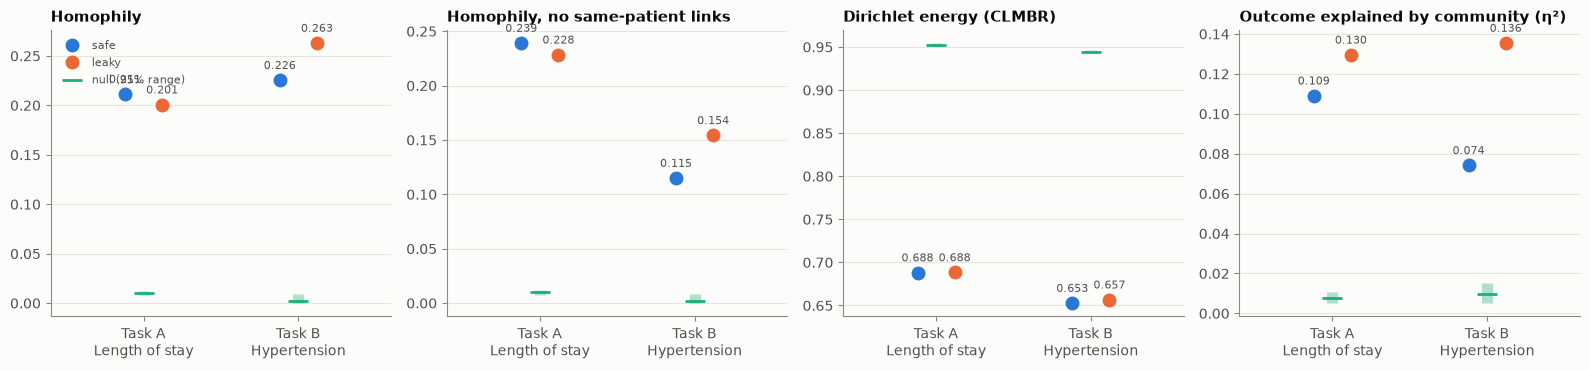

In [3]:
PANELS = [
    ("class_insensitive_homophily", "Homophily"),
    ("class_insensitive_homophily_excl_same_patient", "Homophily, no same-patient links"),
    ("dirichlet_energy_clmbr", "Dirichlet energy (CLMBR)"),
    ("leiden_outcome_eta_squared", "Outcome explained by community (η²)"),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (metric, title) in zip(axes, PANELS, strict=True):
    for x, task in enumerate(TASKS):
        lo, hi = (
            value(task, "null_model", metric, "ci_low"),
            value(task, "null_model", metric, "ci_high"),
        )
        ax.vlines(x, lo, hi, color=nf.COLORS["null"], lw=8, alpha=0.35)
        ax.plot(x, value(task, "null_model", metric), "_", color=nf.COLORS["null"], ms=14, mew=2)
        for dx, cond in ((-0.12, "safe"), (0.12, "leaky")):
            v = value(task, cond, metric)
            ax.plot(x + dx, v, "o", color=nf.COLORS[cond], ms=9, label=cond if x == 0 else None)
            ax.annotate(
                f"{v:.3f}",
                (x + dx, v),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                color=nf.INK_2,
                fontsize=8,
            )
    ax.set_xticks([0, 1], ["Task A\nLength of stay", "Task B\nHypertension"])
    ax.set_xlim(-0.6, 1.6)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=11)
axes[0].plot([], [], "_", color=nf.COLORS["null"], ms=14, mew=2, label="null (95% range)")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
nf.save(fig, figures_dir / "09_cross_task_comparison.png")
plt.show()

## Does the future record contain the answer?

For each task, the largest gap between the share of positive and of negative nodes whose diagnosis vector contains any one code. A gap near 1 would mean a single code nearly *is* the label.

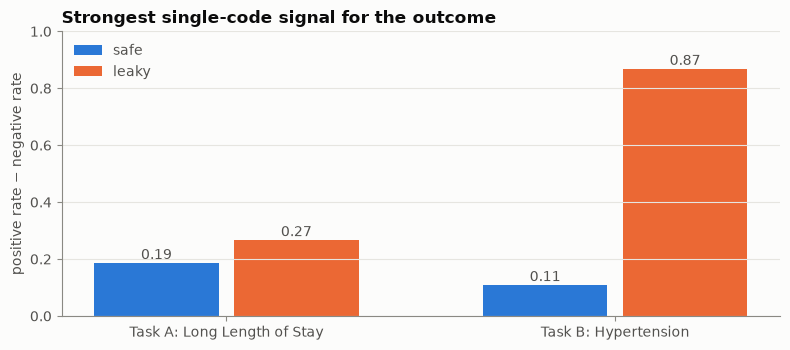

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.36
for i, cond in enumerate(("safe", "leaky")):
    vals = [value(t, cond, "max_single_code_outcome_gap") for t in TASKS]
    bars = ax.bar(
        np.arange(2) + (i - 0.5) * width, vals, width - 0.04, color=nf.COLORS[cond], label=cond
    )
    for b in bars:
        ax.annotate(
            f"{b.get_height():.2f}",
            (b.get_x() + b.get_width() / 2, b.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            color=nf.INK_2,
        )
ax.set_xticks([0, 1], list(TASKS.values()))
ax.set_ylim(0, 1)
ax.set_ylabel("positive rate − negative rate")
ax.set_title("Strongest single-code signal for the outcome")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
nf.save(fig, figures_dir / "09_single_code_leakage.png")
plt.show()

## Findings

**Whether leakage matters depends on whether the outcome is written in the record.** All numbers come from the course OMOP tables (primary results, notebooks 07 and 10).

| | Task A: Long Length of Stay | Task B: Hypertension |
|---|---|---|
| Strongest single code, leaky vectors | 0.27 gap (pleural effusion) | **0.87 gap (essential hypertension itself)** |
| Homophily, leaky − safe | −0.011 | **+0.038** |
| Same, without same-patient links | −0.011 | **+0.039** |
| Outcome explained by community (η²), leaky − safe | +0.020 | **+0.061** |
| Dirichlet energy, leaky − safe | 0.000 | +0.004 |

1. **Task A (long stay): leakage changes the graph's shape, not its outcome signal.** Length of stay is not a diagnosis, so the future record holds no answer key. The links leakage swaps in are slightly worse than the ones it removes.
2. **Task B (hypertension): leakage measurably improves outcome alignment.** The leaky vectors contain the diagnosis being predicted (99.6% of positives against 12.8% of negatives), and homophily without same-patient links rises 34% (0.115 → 0.154). This is where Project 2's leakage warning is most likely to show.
3. **Both real graphs are far from random in both tasks.** Homophily is 0.20–0.26 against null 0.002–0.010. Dirichlet energy is 0.65–0.69 against 0.95. Modularity is 0.92–0.98 against 0.54–0.55.
4. **Same-patient links behave in opposite ways.** They are 29–39% of all links in both tasks. In Task A they *dilute* homophily, because stay length varies for the same person (68% agreement). In Task B they *carry half of it*, because hypertension status persists (95% agreement). Any homophily-vs-gain claim must report both versions.
5. **CLMBR alignment barely moves with leakage** (energy differences of at most 0.004). Leakage changes *which* patients are neighbors, but neighbors look equally alike to CLMBR either way. So any leakage-driven gain in Project 2 would come through the labels the graph lets a model borrow.

Notebook 11 shows all five points survive with billing codes instead of concepts, and with Stanford's official labels instead of rebuilt ones. Task B's leakage gap ranges from +0.038 to +0.056.

### Done when
- [x] #17: both tasks compared through identical code, from aggregate CSVs only (`09_cross_task_comparison.png`, `09_single_code_leakage.png`)